# RQ1: Detection accuracy, missed identifiers, and extra redactions

**Research question:** How accurately can the pipeline detect direct identifiers and quasi-identifiers across cover pages, headers and footers, body text, tables, and images?

(for some of the charts i used ai to generate the code)

In [1]:
import importlib
import logging
import os
import re
import sys
import warnings
from collections import Counter
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("transformers").setLevel(logging.ERROR)

plt.rcParams.update({
    "figure.dpi": 170,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DIRECT_LABELS = ("FULL_NAME", "FIRST_NAME", "LAST_NAME", "Student number", "Institutional email")
QUASI_LABELS = ("Course code", "Group label", "Programme", "Date", "Role")
LABELS = (*DIRECT_LABELS, *QUASI_LABELS)
REGIONS = ("cover", "header", "footer", "body", "body_table", "ocr")

LABEL_DISPLAY = {
    "FULL_NAME": "Full name",
    "FIRST_NAME": "First name",
    "LAST_NAME": "Last name",
    "Student number": "Student ID",
    "Institutional email": "Inst. email",
    "Course code": "Course code",
    "Group label": "Group label",
    "Programme": "Programme",
    "Date": "Date",
    "Role": "Role",
}

REGION_DISPLAY = {
    "cover": "Cover",
    "header": "Header",
    "footer": "Footer",
    "body": "Body text",
    "body_table": "Body table",
    "ocr": "Image/OCR",
}

COLORS = {
    "direct": "#0072B2",
    "quasi": "#E69F00",
    "precision": "#0072B2",
    "recall": "#009E73",
    "f1": "#D55E00",
    "miss": "#CC79A7",
    "extra": "#D55E00",
    "region": "#4E79A7",
    "neutral": "#999999",
}

## 1. Project setup

In [2]:
def find_repo_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / "document_generator").exists() and (p / "thesis_project").exists():
            return p
    return cwd

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from thesis_project.dataset import DatasetManager
from thesis_project.experiments import Experiments
from thesis_project.evaluation import Evaluation, _metrics
from thesis_project.shared import Config, canon, direct, quasi, severity_weight_for
import thesis_project.defender.name_model as name_model

WORK_DIR = ROOT / "notebooks" / "workspace"
DATASET_ROOT = WORK_DIR / "dataset"
MODEL_PATH = WORK_DIR / "tuned_models" / "name_candidate_model.joblib"

HAS_EASYOCR = importlib.util.find_spec("easyocr") is not None
HAS_GLINER = importlib.util.find_spec("gliner") is not None

## 2. Evaluation helpers

In [3]:
def metric_dict(tp, fp, fn):
    return _metrics(int(tp), int(fp), int(fn))


def split_records(records):
    return {
        "train": [r for r in records if r.split == "train"],
        "val": [r for r in records if r.split == "val"],
        "test": [r for r in records if r.split == "test"],
    }


def build_config(run_name, candidate):
    return Config(
        output=WORK_DIR / run_name,
        patterns=True,
        ner=True,
        ocr=HAS_EASYOCR,
        link=True,
        strict=True,
        direct=True,
        quasi=True,
        labels=QUASI_LABELS,
        regions=(),
        pdf=False,
        candidate=str(candidate) if candidate else None,
        ner_backend="hybrid",
        gliner_model="urchade/gliner_multi-v2.1",
        gliner_threshold=0.35,
        fallback=True,
    )


def build_train_df(dm, records):
    frames = []
    for rec in records:
        doc = dm.attach(rec)
        ann = dm.load_annotations(doc)
        names = {
            (e["path"], int(e["start"]), int(e["end"]), e["surface"]): 1
            for e in ann.get("text_entities", [])
            if canon(e.get("label", "")) == "FULL_NAME"
        }
        df = name_model.frame(doc.blocks, names, doc=doc.doc_id)
        if not df.empty:
            frames.append(df)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def ensure_candidate_model(dm, records):
    if MODEL_PATH.exists():
        return MODEL_PATH

    from sklearn.feature_extraction import DictVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score, make_scorer
    from sklearn.model_selection import GridSearchCV, GroupKFold
    from sklearn.pipeline import Pipeline
    import joblib

    train_df = build_train_df(dm, split_records(records)["train"])
    exclude = {"label", "doc_id", "path", "region", "surface", "start", "end", "template_id", "split"}
    feature_columns = [c for c in train_df.columns if c not in exclude]

    pipe = Pipeline([
        ("vectorizer", DictVectorizer(sparse=True)),
        ("classifier", LogisticRegression(max_iter=1500, solver="liblinear", random_state=42)),
    ])

    gs = GridSearchCV(
        pipe,
        {
            "classifier__C": [0.05, 0.1, 0.3, 1.0, 3.0, 10.0],
            "classifier__class_weight": [None, "balanced"],
            "classifier__penalty": ["l2"],
        },
        scoring=make_scorer(f1_score, zero_division=0),
        cv=GroupKFold(n_splits=min(5, train_df["doc_id"].nunique())),
        n_jobs=1,
        refit=True,
    )
    gs.fit(train_df[feature_columns].to_dict(orient="records"), train_df["label"].astype(int), groups=train_df["doc_id"])

    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({
        "pipeline": gs.best_estimator_,
        "feature_columns": feature_columns,
        "cv_best_f1": float(gs.best_score_),
        "model_type": "logistic_regression_name_candidate_classifier",
    }, MODEL_PATH)

    return MODEL_PATH


def reference_annotation_table(dm, docs):
    rows = []
    for rec in docs:
        ann = dm.load_annotations(dm.attach(rec))
        for source_key, source in [("text_entities", "document text"), ("ocr_entities", "image/OCR")]:
            for e in ann.get(source_key, []):
                label = canon(e.get("label", ""))
                rows.append({
                    "doc_id": rec.doc_id,
                    "template_id": rec.template_id,
                    "split": rec.split,
                    "source": source,
                    "region_raw": e.get("region", ""),
                    "region": REGION_DISPLAY.get(e.get("region", ""), e.get("region", "")),
                    "label_raw": label,
                    "label": LABEL_DISPLAY.get(label, label),
                    "class": "direct" if direct(label) else "quasi",
                })
    return pd.DataFrame(rows)


def oracle_result(dm, docs, cfg):
    exp = Experiments(DATASET_ROOT, cfg)
    labels = exp._labels(cfg)
    evaluator = Evaluation()
    rows = []

    for rec in docs:
        doc = dm.attach(rec)
        ann = dm.load_annotations(doc)
        pred = list(ann.get("text_entities", [])) + list(ann.get("ocr_entities", []))
        rows.append({
            "doc_id": rec.doc_id,
            "template_id": rec.template_id,
            "split": rec.split,
            "scores": evaluator.scores(ann, pred),
            "remaining_entities": evaluator.remain(ann, pred, labels),
            "predicted_entities": pred,
        })

    result = exp._sum(rows, labels)
    result["name"] = "PerfectModel oracle"
    return result

In [4]:
def label_metrics_table(result):
    rows = []
    by_region_label = result.get("by_region_label", {})

    for label in LABELS:
        tp = fp = fn = 0
        for region_map in by_region_label.values():
            counts = region_map.get(label, {})
            tp += int(counts.get("tp", 0))
            fp += int(counts.get("fp", 0))
            fn += int(counts.get("fn", 0))

        rows.append({
            "label": LABEL_DISPLAY[label],
            "label_raw": label,
            "class": "direct" if direct(label) else "quasi",
            "reference_mentions": tp + fn,
            "correctly_detected": tp,
            "extra_redactions": fp,
            "missed_identifiers": fn,
            **metric_dict(tp, fp, fn),
        })

    return pd.DataFrame(rows)


def region_metrics_table(result):
    rows = []
    for region in REGIONS:
        counts = result.get("by_region", {}).get(region, {})
        tp = int(counts.get("tp", 0))
        fp = int(counts.get("fp", 0))
        fn = int(counts.get("fn", 0))

        rows.append({
            "region": REGION_DISPLAY[region],
            "region_raw": region,
            "reference_mentions": tp + fn,
            "correctly_detected": tp,
            "extra_redactions": fp,
            "missed_identifiers": fn,
            **metric_dict(tp, fp, fn),
        })

    return pd.DataFrame(rows)


def class_metrics_table(result):
    rows = []
    by_region_label = result.get("by_region_label", {})

    for cls, labels in [("direct identifiers", DIRECT_LABELS), ("quasi-identifiers", QUASI_LABELS)]:
        tp = fp = fn = 0
        for region_map in by_region_label.values():
            for label in labels:
                counts = region_map.get(label, {})
                tp += int(counts.get("tp", 0))
                fp += int(counts.get("fp", 0))
                fn += int(counts.get("fn", 0))

        rows.append({
            "identifier_type": cls,
            "reference_mentions": tp + fn,
            "correctly_detected": tp,
            "extra_redactions": fp,
            "missed_identifiers": fn,
            **metric_dict(tp, fp, fn),
        })

    return pd.DataFrame(rows)


def region_label_metrics_table(result):
    rows = []
    by_region_label = result.get("by_region_label", {})

    for region in REGIONS:
        for label in LABELS:
            counts = by_region_label.get(region, {}).get(label, {})
            tp = int(counts.get("tp", 0))
            fp = int(counts.get("fp", 0))
            fn = int(counts.get("fn", 0))
            rows.append({
                "region": REGION_DISPLAY[region],
                "region_raw": region,
                "label": LABEL_DISPLAY[label],
                "label_raw": label,
                "class": "direct" if direct(label) else "quasi",
                "reference_mentions": tp + fn,
                "correctly_detected": tp,
                "extra_redactions": fp,
                "missed_identifiers": fn,
                **metric_dict(tp, fp, fn),
            })

    return pd.DataFrame(rows)


def remaining_entities_table(result):
    rows = []
    for row in result.get("per_document", []):
        for e in row.get("remaining_entities", []):
            label = canon(e.get("label", ""))
            rows.append({
                "document": row.get("doc_id"),
                "template": row.get("template_id"),
                "region": REGION_DISPLAY.get(e.get("region", ""), e.get("region", "")),
                "region_raw": e.get("region", ""),
                "label": LABEL_DISPLAY.get(label, label),
                "label_raw": label,
                "class": "direct" if direct(label) else "quasi",
                "surface": e.get("surface", ""),
                "severity_weight": severity_weight_for(label),
            })

    return pd.DataFrame(rows)


def clean_metric_table(df, first_col):
    table = df[[first_col, "reference_mentions", "correctly_detected", "extra_redactions", "missed_identifiers", "precision", "recall", "f1"]].copy()
    table[["precision", "recall", "f1"]] = table[["precision", "recall", "f1"]].round(3)
    return table

## 3. Detailed prediction matching for false-positive inspection

The official precision/recall/F1 values come from the evaluator. The detailed false-positive tables below reconstruct which predicted spans look like extra redactions so that their surfaces, regions, and detector provenance can be inspected.

In [5]:
def entity_value(entity, key, default=""):
    if isinstance(entity, dict):
        return entity.get(key, default)
    return getattr(entity, key, default)


def norm_surface(s):
    return re.sub(r"\s+", " ", str(s or "").strip()).lower()


def safe_int(x, default=-1):
    try:
        return int(x)
    except Exception:
        return default


def entity_label(e):
    return canon(str(entity_value(e, "label", "")))


def entity_region(e):
    return str(entity_value(e, "region", ""))


def entity_surface(e):
    return str(entity_value(e, "surface", ""))


def entity_path(e):
    return str(entity_value(e, "path", entity_value(e, "block_path", entity_value(e, "block_id", ""))))


def entity_start(e):
    return safe_int(entity_value(e, "start", -1))


def entity_end(e):
    return safe_int(entity_value(e, "end", -1))


def exact_key(e):
    return (entity_path(e), entity_start(e), entity_end(e), entity_label(e))


def relaxed_surface_key(e):
    return (entity_region(e), entity_label(e), norm_surface(entity_surface(e)))


def detector_provenance(e):
    parts = []
    keys = [
        "detector", "component", "source", "origin", "method", "rule", "rule_name",
        "backend", "stage", "provenance", "created_by", "kind", "reason", "confidence", "score"
    ]

    for key in keys:
        if isinstance(e, dict):
            has_key = key in e
            value = e.get(key)
        else:
            has_key = hasattr(e, key)
            value = getattr(e, key, None)

        if not has_key:
            continue
        if isinstance(value, (str, int, float, bool)):
            parts.append(f"{key}={value}")
        elif isinstance(value, dict):
            short = ", ".join(f"{k}={v}" for k, v in list(value.items())[:4])
            parts.append(f"{key}={{ {short} }}")
        elif isinstance(value, list):
            parts.append(f"{key}={value[:4]}")

    return " | ".join(parts) if parts else "not recorded"


def coarse_detector_group(provenance):
    p = str(provenance).lower()
    if any(x in p for x in ["pattern", "regex", "rule"]):
        return "Pattern / rule"
    if "gliner" in p:
        return "GLiNER"
    if any(x in p for x in ["ner", "hybrid", "model"]):
        return "NER / hybrid"
    if any(x in p for x in ["ocr", "image"]):
        return "OCR-related"
    if any(x in p for x in ["link", "propagat"]):
        return "Cross-region linking"
    return "Not recorded"


def classify_date_surface(surface):
    s = norm_surface(surface)
    month_words = (
        "january|february|march|april|may|june|july|august|"
        "september|october|november|december|"
        "jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec"
    )
    weekday_words = (
        "monday|tuesday|wednesday|thursday|friday|saturday|sunday|"
        "mon|tue|wed|thu|fri|sat|sun"
    )

    if not s:
        return "empty"
    if re.fullmatch(r"(19|20)\d{2}", s):
        return "standalone year"
    if re.fullmatch(r"\d{1,2}[/-]\d{1,2}([/-]\d{2,4})?", s):
        return "numeric date"
    if re.fullmatch(r"\d{4}[/-]\d{1,2}[/-]\d{1,2}", s):
        return "numeric date"
    if re.search(rf"\b({month_words})\b", s):
        return "month-name date"
    if re.search(rf"\b({weekday_words})\b", s):
        return "weekday"
    if re.search(r"\d{1,2}:\d{2}", s):
        return "time"
    if re.search(r"\b(week|weeks|semester|period|quarter|q[1-4])\b", s):
        return "period / schedule term"
    if re.search(r"[-–—]", s) and re.search(r"\d", s):
        return "range-like"
    if re.fullmatch(r"\d{1,2}", s):
        return "small standalone number"
    if re.search(r"\d", s):
        return "other number/date-like"
    return "other text"


def prediction_detail_table(dm, docs, result):
    reference_exact = {}
    reference_relaxed = {}

    for rec in docs:
        ann = dm.load_annotations(dm.attach(rec))
        entities = list(ann.get("text_entities", [])) + list(ann.get("ocr_entities", []))
        reference_exact[rec.doc_id] = Counter(exact_key(e) for e in entities)
        reference_relaxed[rec.doc_id] = Counter(relaxed_surface_key(e) for e in entities)

    rows = []
    for row in result.get("per_document", []):
        doc_id = row.get("doc_id")
        exact_counter = reference_exact.get(doc_id, Counter()).copy()
        relaxed_counter = reference_relaxed.get(doc_id, Counter()).copy()

        for e in row.get("predicted_entities", []):
            label = entity_label(e)
            region = entity_region(e)
            surface = entity_surface(e)
            provenance = detector_provenance(e)

            matched = False
            key_exact = exact_key(e)
            if exact_counter[key_exact] > 0:
                exact_counter[key_exact] -= 1
                matched = True
                match_type = "exact"
            else:
                key_relaxed = relaxed_surface_key(e)
                if relaxed_counter[key_relaxed] > 0:
                    relaxed_counter[key_relaxed] -= 1
                    matched = True
                    match_type = "relaxed surface"
                else:
                    match_type = "none"

            rows.append({
                "document": doc_id,
                "template": row.get("template_id"),
                "region": REGION_DISPLAY.get(region, region),
                "region_raw": region,
                "label": LABEL_DISPLAY.get(label, label),
                "label_raw": label,
                "class": "direct" if direct(label) else "quasi" if quasi(label) else "other",
                "surface": surface,
                "normalised_surface": norm_surface(surface),
                "status": "matched reference" if matched else "extra redaction",
                "match_type": match_type,
                "provenance": provenance,
                "detector_group": coarse_detector_group(provenance),
                "surface_type": classify_date_surface(surface) if label == "Date" else "",
                "start": entity_start(e),
                "end": entity_end(e),
                "path": entity_path(e),
            })

    return pd.DataFrame(rows)

## 4. Plot helpers

In [6]:
def add_bar_labels(ax, bars, offset=3, fontsize=9, fmt="{:.0f}"):
    ymax = max([b.get_height() for b in bars] + [1])
    for b in bars:
        h = b.get_height()
        if h > 0:
            ax.text(b.get_x() + b.get_width() / 2, h + offset, fmt.format(h), ha="center", va="bottom", fontsize=fontsize)
    ax.set_ylim(0, ymax * 1.15)


def setup_axis(ax, ylabel, xlabel=None):
    ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.grid(axis="y", linestyle=":", linewidth=0.8, alpha=0.65)
    ax.set_axisbelow(True)


def plot_evaluation_set(reference_df):
    region_counts = reference_df.groupby("region_raw").size().reindex(REGIONS, fill_value=0)
    label_counts = reference_df.groupby("label_raw").size().reindex(LABELS, fill_value=0)

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)

    x1 = [REGION_DISPLAY[r] for r in region_counts.index]
    bars1 = axes[0].bar(x1, region_counts.values, color=COLORS["region"])
    axes[0].set_title("Reference identifiers are concentrated in body text, tables, and cover pages", pad=12)
    setup_axis(axes[0], "Reference identifier mentions")
    axes[0].tick_params(axis="x", rotation=25)
    add_bar_labels(axes[0], bars1, offset=8)

    x2 = [LABEL_DISPLAY[l] for l in label_counts.index]
    colors = [COLORS["direct"] if direct(l) else COLORS["quasi"] for l in label_counts.index]
    bars2 = axes[1].bar(x2, label_counts.values, color=colors)
    axes[1].set_title("The test set is dominated by direct name identifiers", pad=12)
    setup_axis(axes[1], "Reference identifier mentions")
    axes[1].tick_params(axis="x", rotation=35)
    add_bar_labels(axes[1], bars2, offset=8)

    from matplotlib.patches import Patch
    axes[1].legend(
        handles=[
            Patch(facecolor=COLORS["direct"], label="Direct identifier"),
            Patch(facecolor=COLORS["quasi"], label="Quasi-identifier"),
        ],
        frameon=False,
        loc="upper right",
    )

    plt.show()


def plot_metric_bars(df, x_col, title, rotation=0):
    fig, ax = plt.subplots(figsize=(max(9, len(df) * 0.95), 5.4), constrained_layout=True)
    x = np.arange(len(df))
    w = 0.24

    ax.bar(x - w, df["precision"], width=w, color=COLORS["precision"], label="Precision")
    ax.bar(x, df["recall"], width=w, color=COLORS["recall"], label="Recall")
    ax.bar(x + w, df["f1"], width=w, color=COLORS["f1"], label="F1")

    labels = [f"{row[x_col]}\n(n={int(row['reference_mentions'])})" for _, row in df.iterrows()]
    ax.set_title(title, pad=32)
    setup_axis(ax, "Score")
    ax.set_ylim(0, 1.12)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotation, ha="right" if rotation else "center")
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.10))

    plt.show()


def plot_error_overview(label_df, remaining_summary):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.9), constrained_layout=True)

    if remaining_summary.empty:
        miss_labels = ["No remaining misses"]
        miss_values = [0]
    else:
        miss_data = remaining_summary.copy()
        miss_data["cell"] = miss_data["region"] + "\n" + miss_data["label"]
        miss_labels = miss_data["cell"].tolist()
        miss_values = miss_data["missed_identifiers"].tolist()

    bars1 = axes[0].bar(miss_labels, miss_values, color=COLORS["miss"])
    axes[0].set_title("Missed identifiers are few and concentrated", pad=12)
    setup_axis(axes[0], "Missed identifiers")
    axes[0].tick_params(axis="x", rotation=0)
    add_bar_labels(axes[0], bars1, offset=0.05)
    axes[0].set_ylim(0, max(miss_values + [1]) + 0.8)

    extra_data = label_df.sort_values("extra_redactions", ascending=False).copy()
    extra_data["wrapped_label"] = extra_data["label"].apply(lambda s: fill(s, 10))
    colors = [COLORS["direct"] if c == "direct" else COLORS["quasi"] for c in extra_data["class"]]
    bars2 = axes[1].bar(extra_data["wrapped_label"], extra_data["extra_redactions"], color=colors)
    axes[1].set_title("Extra redactions are dominated by Date detections", pad=12)
    setup_axis(axes[1], "Extra redactions")
    axes[1].tick_params(axis="x", rotation=35)
    add_bar_labels(axes[1], bars2, offset=12, fontsize=8)

    from matplotlib.patches import Patch
    axes[1].legend(
        handles=[
            Patch(facecolor=COLORS["direct"], label="Direct identifier"),
            Patch(facecolor=COLORS["quasi"], label="Quasi-identifier"),
        ],
        frameon=False,
        loc="upper right",
    )

    plt.show()


def plot_region_label_error_heatmaps(region_label_df):
    miss = region_label_df.pivot_table(index="region", columns="label", values="missed_identifiers", aggfunc="sum", fill_value=0)
    extra = region_label_df.pivot_table(index="region", columns="label", values="extra_redactions", aggfunc="sum", fill_value=0)
    row_order = [REGION_DISPLAY[r] for r in REGIONS]
    col_order = [LABEL_DISPLAY[l] for l in LABELS]
    miss = miss.reindex(index=row_order, columns=col_order, fill_value=0)
    extra = extra.reindex(index=row_order, columns=col_order, fill_value=0)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), constrained_layout=True)
    for ax, matrix, title, cmap in [
        (axes[0], miss, "Missed identifiers by document region and identifier label", "Reds"),
        (axes[1], extra, "False-positive redactions by document region and identifier label", "Oranges"),
    ]:
        im = ax.imshow(matrix.values, aspect="auto", cmap=cmap)
        ax.set_title(title, pad=12)
        ax.set_xticks(np.arange(matrix.shape[1]))
        ax.set_xticklabels(matrix.columns, rotation=35, ha="right")
        ax.set_yticks(np.arange(matrix.shape[0]))
        ax.set_yticklabels(matrix.index)
        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                value = int(matrix.iloc[i, j])
                if value:
                    ax.text(j, i, str(value), ha="center", va="center", fontsize=9, fontweight="bold")
        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("Count")

    plt.show()

## 5. Run the RQ1 evaluation

The evaluation itself is captured so that the notebook output stays focused on the thesis-ready tables and figures.

In [7]:
%%capture rq1_run_log

dm = DatasetManager(DATASET_ROOT)
records = dm.load_manifest()
model_path = ensure_candidate_model(dm, records)
cfg = build_config("rq1_full_pipeline", model_path)

exp = Experiments(DATASET_ROOT, cfg)
docs = exp.rq1_documents()
reference_df = reference_annotation_table(dm, docs)

oracle = oracle_result(dm, docs, cfg)
rq1_result = exp.rq1()

label_df = label_metrics_table(rq1_result)
region_df = region_metrics_table(rq1_result)
class_df = class_metrics_table(rq1_result)
region_label_df = region_label_metrics_table(rq1_result)
remaining_df = remaining_entities_table(rq1_result)
prediction_detail_df = prediction_detail_table(dm, docs, rq1_result)

In [8]:
scope_df = pd.DataFrame([{
    "documents": len(docs),
    "reference_identifier_mentions": len(reference_df),
    "direct_identifier_mentions": int((reference_df["class"] == "direct").sum()),
    "quasi_identifier_mentions": int((reference_df["class"] == "quasi").sum()),
    "document_regions": reference_df["region"].nunique(),
    "image_ocr_mentions": int((reference_df["source"] == "image/OCR").sum()),
}])

oracle_df = pd.DataFrame([oracle["overall"]])[["tp", "fp", "fn", "precision", "recall", "f1"]].rename(columns={
    "tp": "correctly_detected",
    "fp": "extra_redactions",
    "fn": "missed_identifiers",
}).round(3)

overall_df = pd.DataFrame([rq1_result["overall"]])[["tp", "fp", "fn", "precision", "recall", "f1"]].rename(columns={
    "tp": "correctly_detected",
    "fp": "extra_redactions",
    "fn": "missed_identifiers",
}).round(3)

if remaining_df.empty:
    remaining_summary = pd.DataFrame(columns=["region", "label", "class", "missed_identifiers"])
else:
    remaining_summary = (
        remaining_df.groupby(["region", "label", "class"])
        .size()
        .reset_index(name="missed_identifiers")
        .sort_values(["missed_identifiers", "region", "label"], ascending=[False, True, True])
        .reset_index(drop=True)
    )

extra_by_label = label_df[["label", "class", "reference_mentions", "extra_redactions", "precision"]].copy()
extra_by_label["extra_redactions_per_100_reference"] = 100 * extra_by_label["extra_redactions"] / extra_by_label["reference_mentions"]
extra_by_label = extra_by_label.sort_values("extra_redactions", ascending=False).reset_index(drop=True)

extra_by_region = region_df[["region", "reference_mentions", "extra_redactions", "precision"]].copy()
extra_by_region["extra_redactions_per_100_reference"] = 100 * extra_by_region["extra_redactions"] / extra_by_region["reference_mentions"]
extra_by_region = extra_by_region.sort_values("extra_redactions", ascending=False).reset_index(drop=True)

extra_region_label = (
    region_label_df[region_label_df["extra_redactions"] > 0]
    .sort_values("extra_redactions", ascending=False)
    .reset_index(drop=True)
)

all_extra_detail_df = prediction_detail_df[prediction_detail_df["status"] == "extra redaction"].copy()

## 6. Core RQ1 tables

In [9]:
display(Markdown("### Evaluation scope"))
display(scope_df)

display(Markdown("### PerfectModel sanity check"))
display(oracle_df)

display(Markdown("### Full pipeline overall result"))
display(overall_df)

display(Markdown("### Direct identifiers vs quasi-identifiers"))
display(clean_metric_table(class_df, "identifier_type"))

display(Markdown("### Region-level performance"))
display(clean_metric_table(region_df, "region"))

display(Markdown("### Label-level performance"))
display(clean_metric_table(label_df, "label"))

### Evaluation scope

,documents,reference_identifier_mentions,direct_identifier_mentions,quasi_identifier_mentions,document_regions,image_ocr_mentions
0,84,8768,8306,462,6,148


### PerfectModel sanity check

,correctly_detected,extra_redactions,missed_identifiers,precision,recall,f1
0,8768,0,0,1.0,1.0,1.0


### Full pipeline overall result

,correctly_detected,extra_redactions,missed_identifiers,precision,recall,f1
0,8750,3768,18,0.699,0.998,0.822


... (2 outputs left out)

### Region-level performance

,region,reference_mentions,correctly_detected,extra_redactions,missed_identifiers,precision,recall,f1
0,Cover,2421,2408,92,13,0.963,0.995,0.979
1,Header,72,72,156,0,0.316,1.000,0.480
2,Footer,82,82,136,0,0.376,1.000,0.547
3,Body text,3843,3843,1526,0,0.716,1.000,0.834
4,Body table,2202,2197,1378,5,0.615,0.998,0.761
5,Image/OCR,148,148,480,0,0.236,1.000,0.381


### Label-level performance

,label,reference_mentions,correctly_detected,extra_redactions,missed_identifiers,precision,recall,f1
0,Full name,2712,2711,213,1,0.927,1.000,0.962
1,First name,2567,2563,360,4,0.877,0.998,0.934
2,Last name,2564,2563,361,1,0.877,1.000,0.934
3,Student ID,407,395,0,12,1.000,0.971,0.985
4,Inst. email,56,56,8,0,0.875,1.000,0.933
5,Course code,78,78,20,0,0.796,1.000,0.886
6,Group label,107,107,123,0,0.465,1.000,0.635
7,Programme,42,42,28,0,0.600,1.000,0.750
8,Date,95,95,2603,0,0.035,1.000,0.068
9,Role,140,140,52,0,0.729,1.000,0.843


## 7. Core RQ1 thesis figures

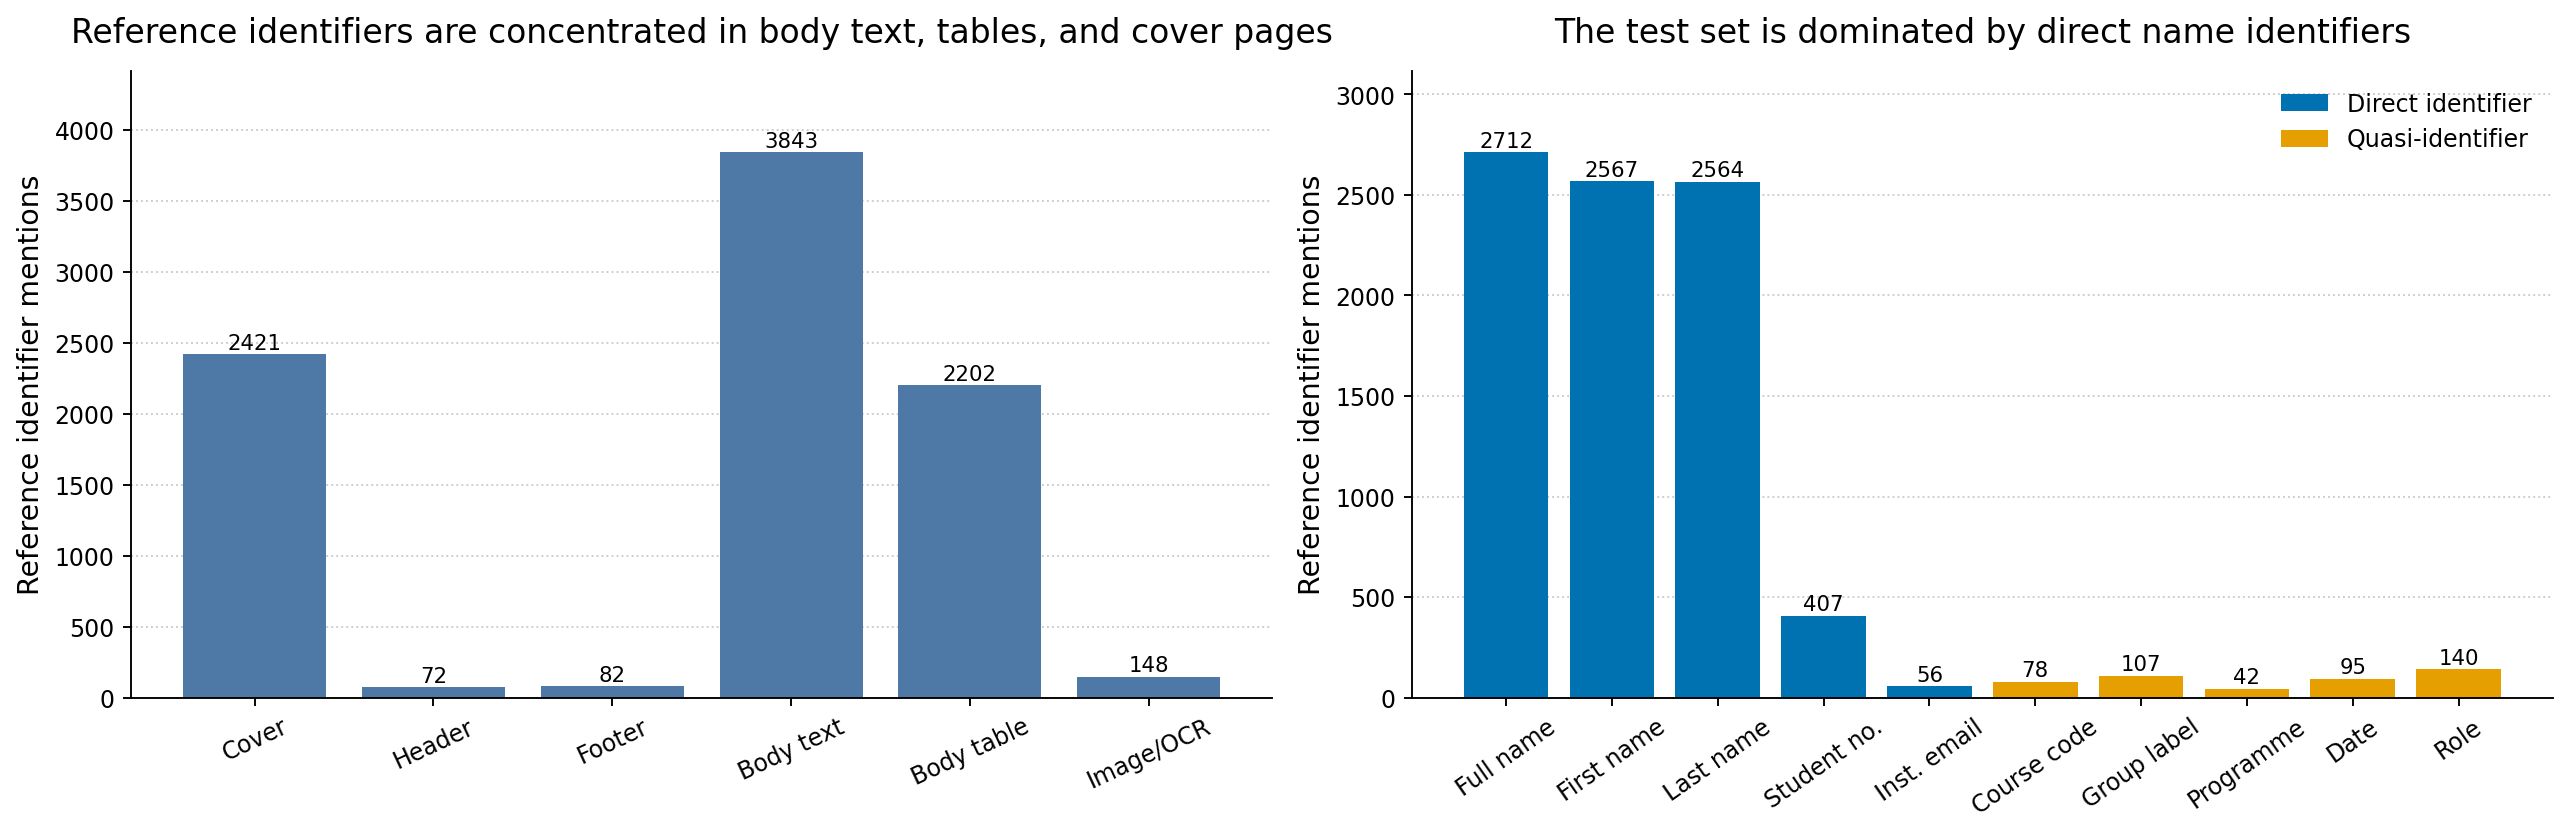

In [10]:
plot_evaluation_set(reference_df)

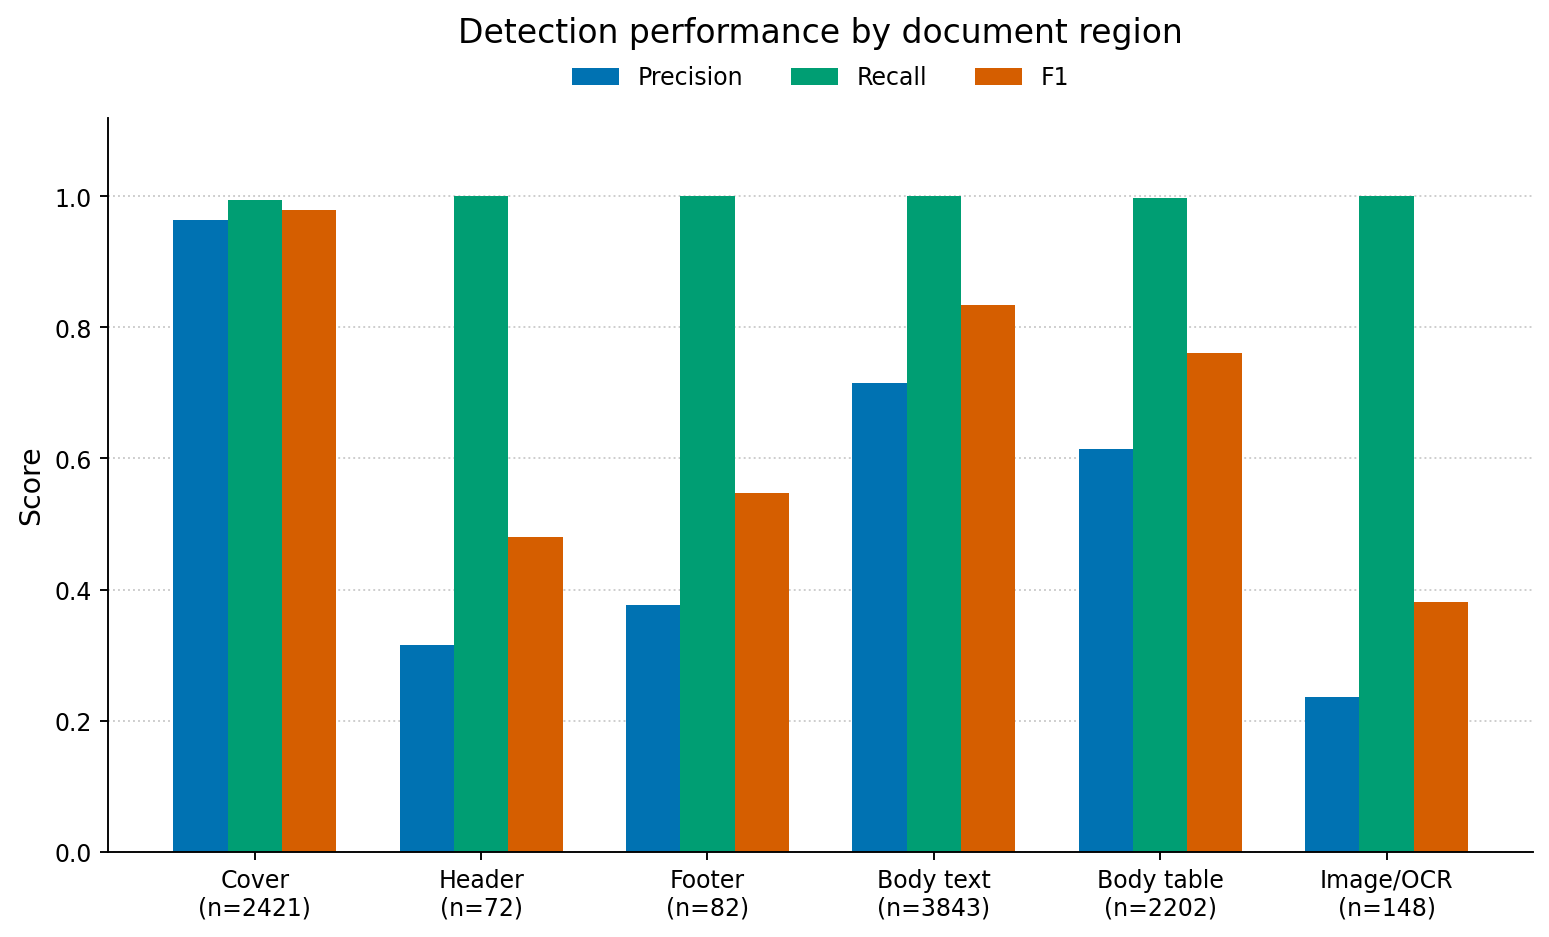

In [11]:
plot_metric_bars(
    region_df,
    "region",
    "Detection performance by document region",
    rotation=0,
)

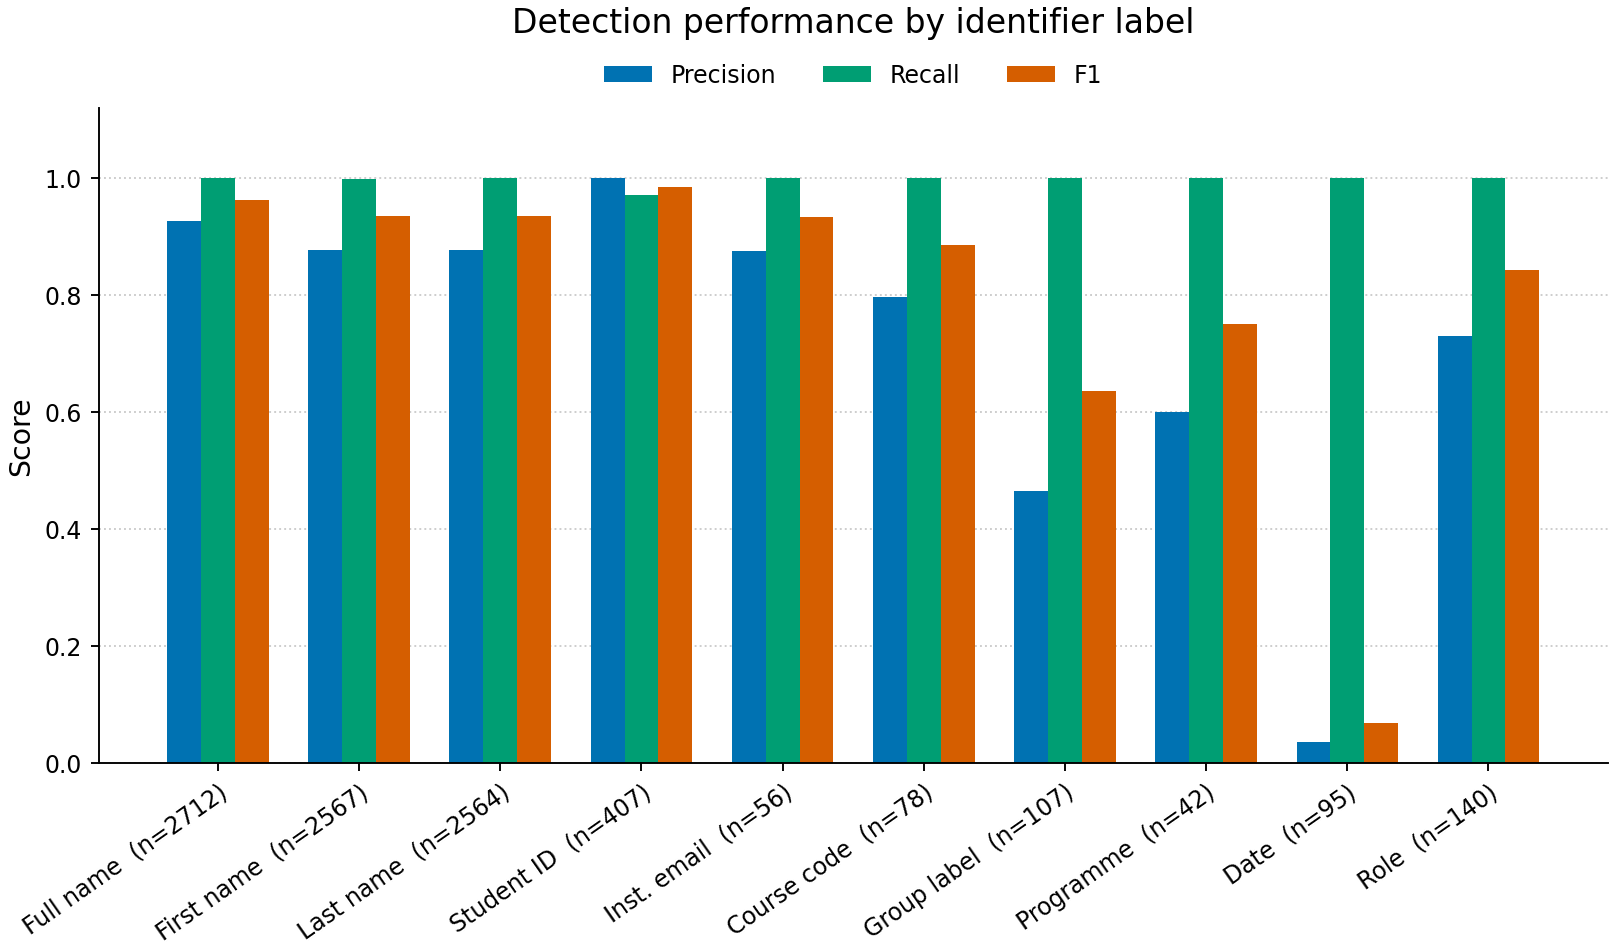

In [12]:
plot_metric_bars(
    label_df,
    "label",
    "Detection performance by identifier label",
    rotation=35,
)

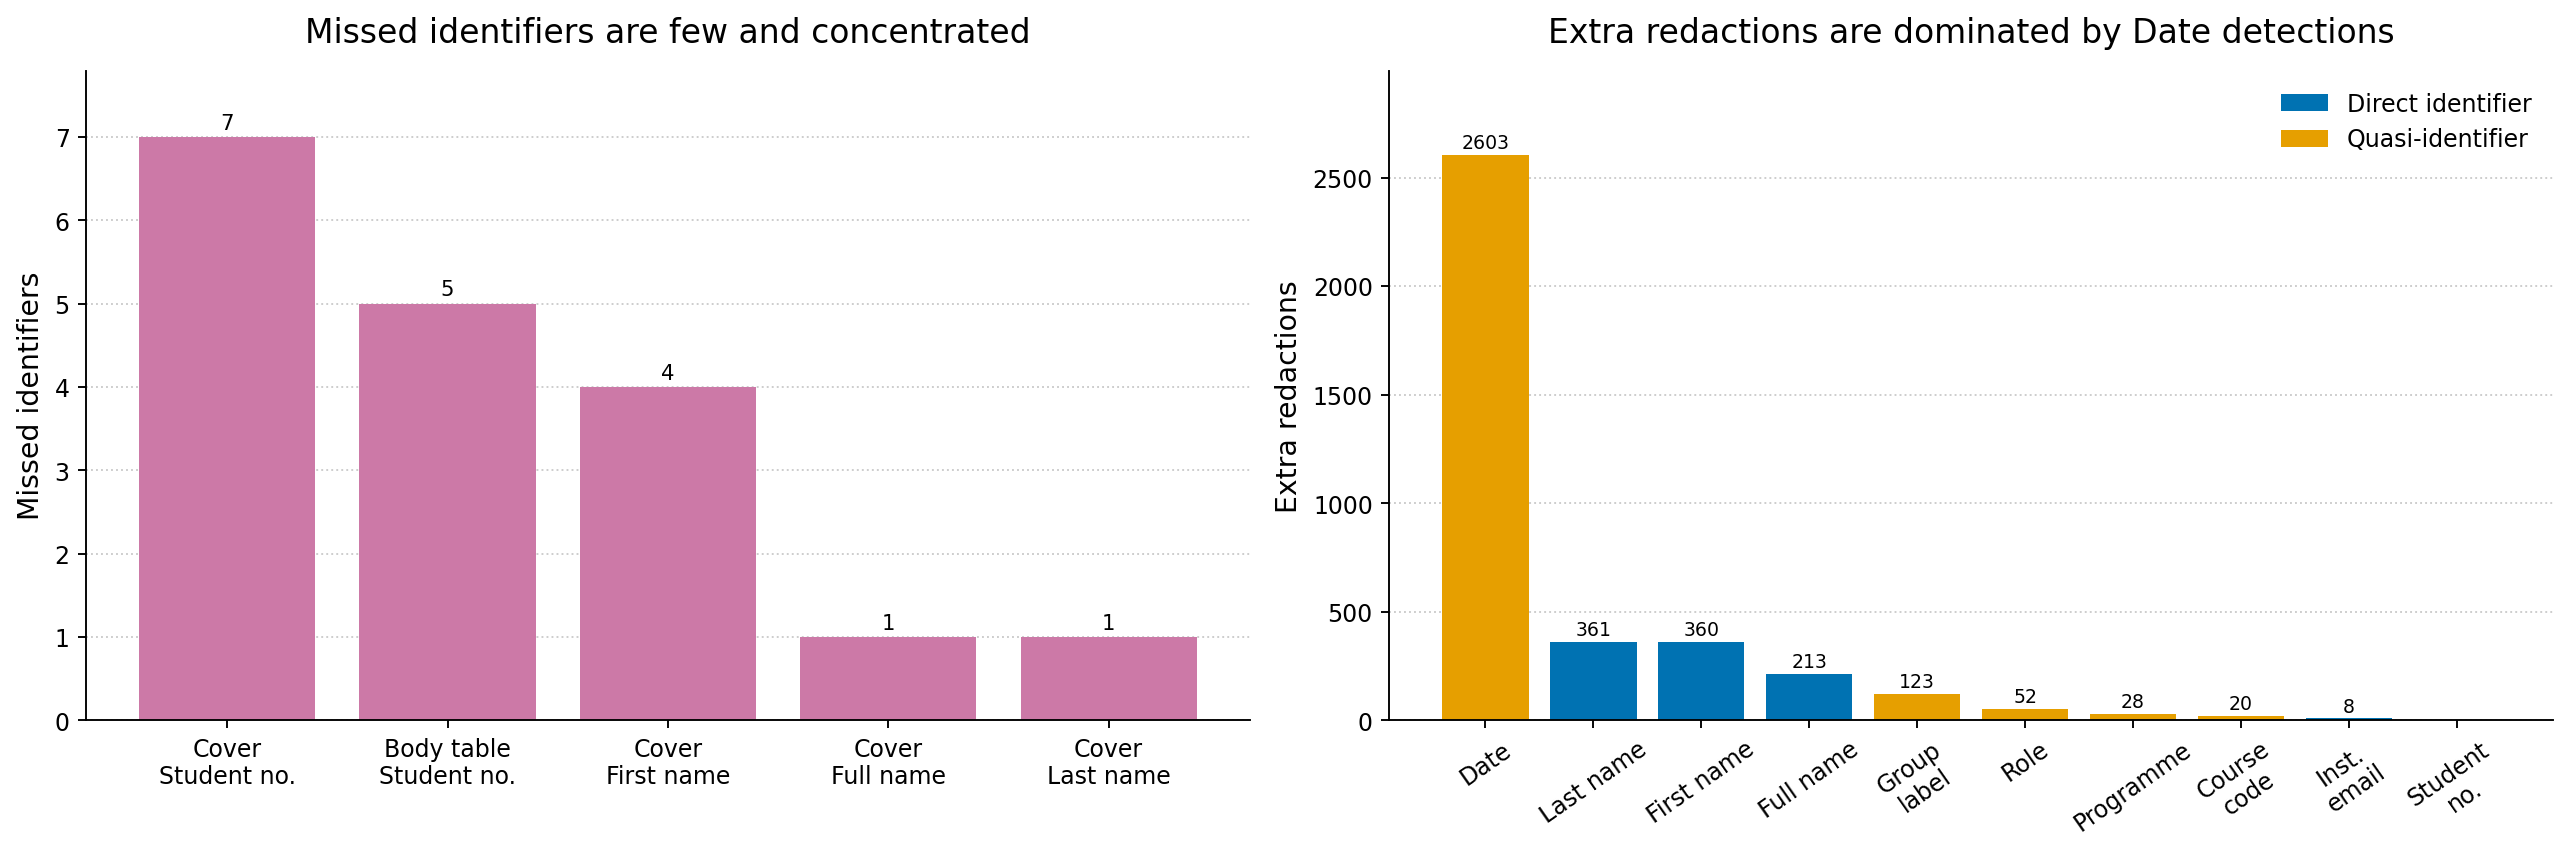

In [13]:
plot_error_overview(label_df, remaining_summary)

## 8. False-negative analysis: what remains visible?

False negatives are the privacy-critical errors because they are reference identifiers that the system failed to detect. This section therefore asks where the remaining visible identifiers are located and what kind of identifiers they are.

In [14]:
display(Markdown("### Remaining missed identifiers by region and label"))
display(remaining_summary)

display(Markdown("### Remaining missed identifiers with surfaces"))
display(
    remaining_df[["document", "template", "region", "label", "class", "surface", "severity_weight"]]
    .sort_values(["severity_weight", "region", "label"], ascending=[False, True, True])
    if not remaining_df.empty else remaining_df
)

miss_by_region = (
    region_df[["region", "reference_mentions", "missed_identifiers", "recall"]]
    .sort_values("missed_identifiers", ascending=False)
    .reset_index(drop=True)
)

miss_by_label = (
    label_df[["label", "class", "reference_mentions", "missed_identifiers", "recall"]]
    .sort_values("missed_identifiers", ascending=False)
    .reset_index(drop=True)
)

display(Markdown("### Missed identifiers by document region"))
display(miss_by_region)

display(Markdown("### Missed identifiers by identifier label"))
display(miss_by_label)

### Remaining missed identifiers by region and label

,region,label,class,missed_identifiers
0,Cover,Student ID,direct,7
1,Body table,Student ID,direct,5
2,Cover,First name,direct,4
3,Cover,Full name,direct,1
4,Cover,Last name,direct,1


### Remaining missed identifiers with surfaces

,document,template,region,label,class,surface,severity_weight
1,doc_00097_project_plan,project_plan,Body table,Student ID,direct,i631103,3.0
6,doc_00171_project_plan,project_plan,Body table,Student ID,direct,i617068,3.0
8,doc_00225_project_plan,project_plan,Body table,Student ID,direct,i631682,3.0
15,doc_00470_project_plan,project_plan,Body table,Student ID,direct,i316352,3.0
17,doc_00497_project_plan,project_plan,Body table,Student ID,direct,i615069,3.0
3,doc_00104_agenda,agenda,Cover,Full name,direct,Russell Stanley,3.0
0,doc_00031_agenda,agenda,Cover,Student ID,direct,i631490,3.0
7,doc_00224_minutes,minutes,Cover,Student ID,direct,i631790,3.0
9,doc_00266_agenda,agenda,Cover,Student ID,direct,i316898,3.0
11,doc_00311_minutes,minutes,Cover,Student ID,direct,i631444,3.0


### Missed identifiers by document region

,region,reference_mentions,missed_identifiers,recall
0,Cover,2421,13,0.994630
1,Body table,2202,5,0.997729
2,Header,72,0,1.000000
3,Footer,82,0,1.000000
4,Body text,3843,0,1.000000
5,Image/OCR,148,0,1.000000


### Missed identifiers by identifier label

,label,class,reference_mentions,missed_identifiers,recall
0,Student ID,direct,407,12,0.970516
1,First name,direct,2567,4,0.998442
2,Full name,direct,2712,1,0.999631
3,Last name,direct,2564,1,0.999610
4,Inst. email,direct,56,0,1.000000
5,Course code,quasi,78,0,1.000000
6,Group label,quasi,107,0,1.000000
7,Programme,quasi,42,0,1.000000
8,Date,quasi,95,0,1.000000
9,Role,quasi,140,0,1.000000


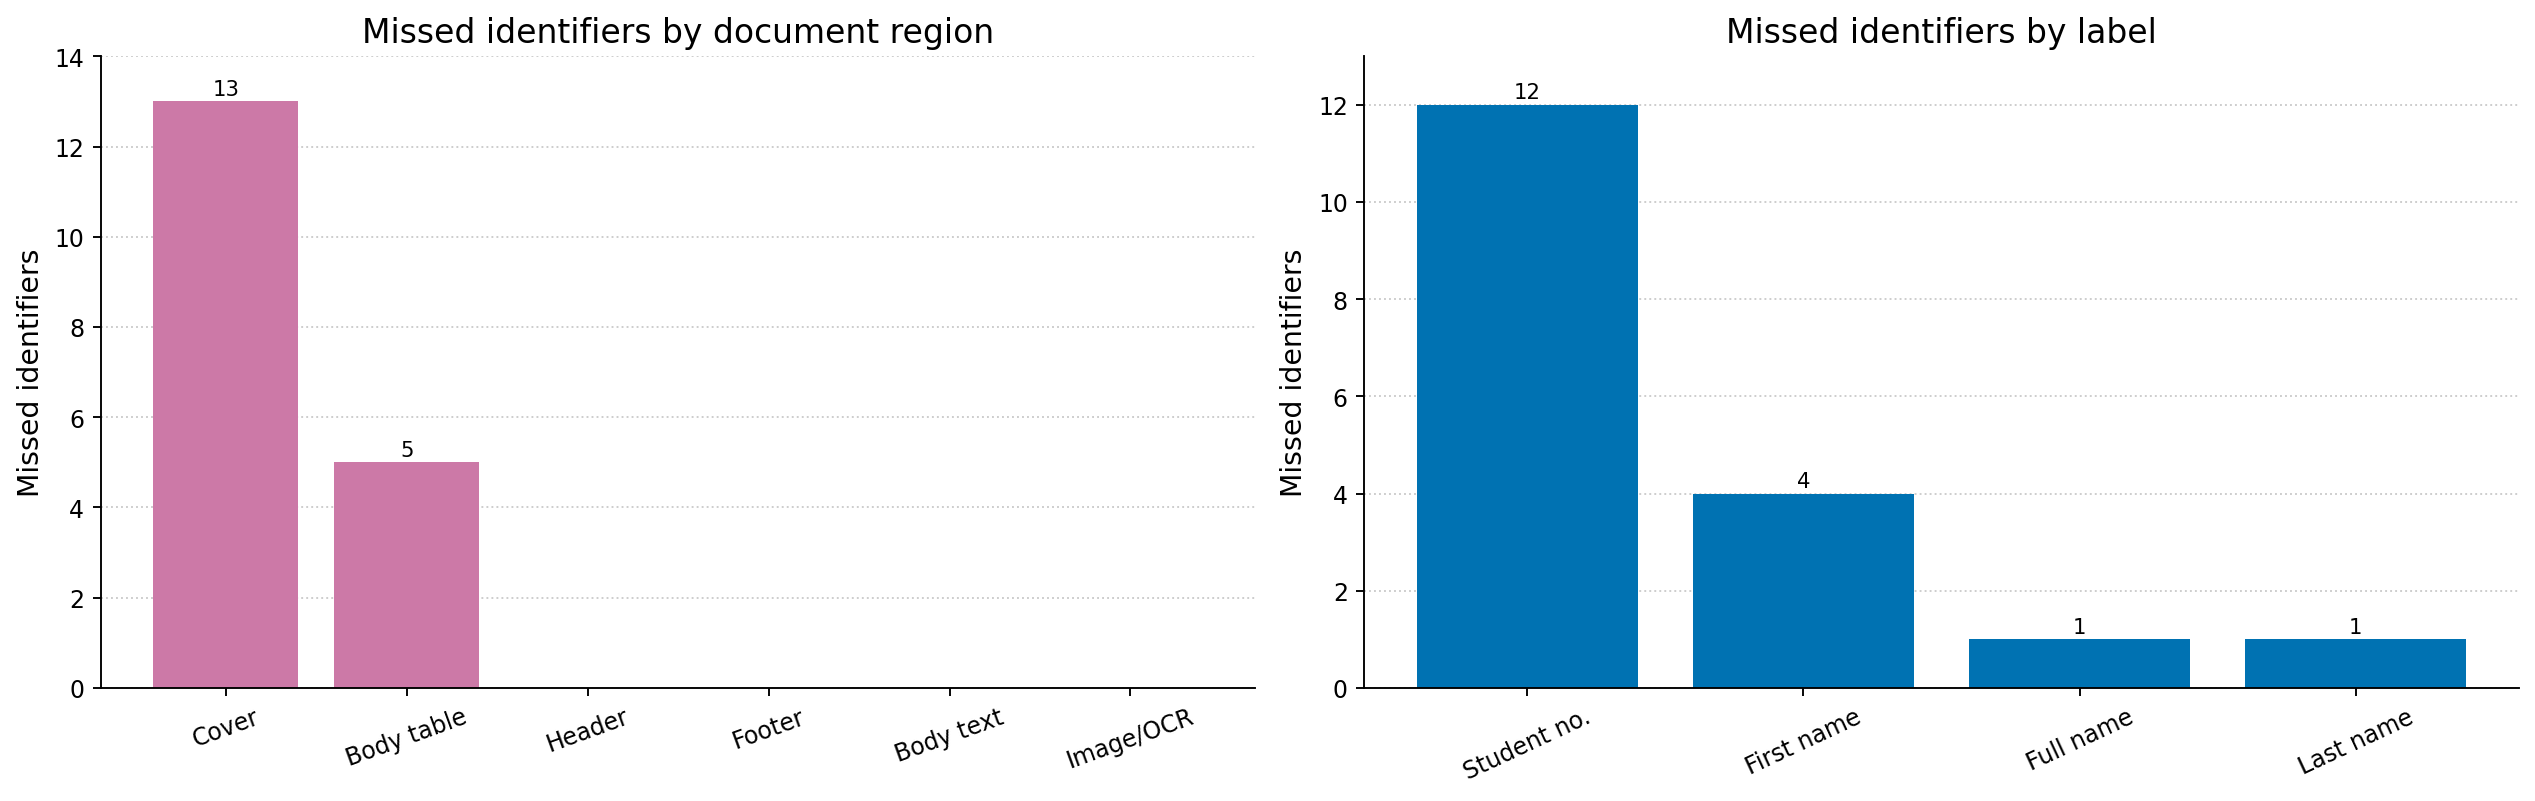

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14.8, 4.6), constrained_layout=True)

miss_region_plot = miss_by_region.sort_values("missed_identifiers", ascending=False)
bars = axes[0].bar(miss_region_plot["region"], miss_region_plot["missed_identifiers"], color=COLORS["miss"])
axes[0].set_title("Missed identifiers by document region")
setup_axis(axes[0], "Missed identifiers")
axes[0].tick_params(axis="x", rotation=20)
add_bar_labels(axes[0], bars, offset=0.05)
axes[0].set_ylim(0, max(miss_region_plot["missed_identifiers"].max(), 1) + 1)

miss_label_plot = miss_by_label[miss_by_label["missed_identifiers"] > 0].copy()
if miss_label_plot.empty:
    miss_label_plot = pd.DataFrame({"label": ["No remaining misses"], "class": ["direct"], "missed_identifiers": [0]})
colors = [COLORS["direct"] if c == "direct" else COLORS["quasi"] for c in miss_label_plot["class"]]
bars = axes[1].bar(miss_label_plot["label"], miss_label_plot["missed_identifiers"], color=colors)
axes[1].set_title("Missed identifiers by label")
setup_axis(axes[1], "Missed identifiers")
axes[1].tick_params(axis="x", rotation=25)
add_bar_labels(axes[1], bars, offset=0.05)
axes[1].set_ylim(0, max(miss_label_plot["missed_identifiers"].max(), 1) + 1)

plt.show()

## 9. False-positive analysis: what is over-redacted?

False positives are not privacy leaks, but they matter because they reduce document utility and explain why precision is lower than recall. This section analyses extra redactions by label, region, and region-label cell.

In [16]:
display(Markdown("### Extra redactions by identifier label"))
display(extra_by_label.round(3))

display(Markdown("### Extra redactions by document region"))
display(extra_by_region.round(3))

display(Markdown("### Largest extra-redaction region-label cells"))
display(
    extra_region_label[["region", "label", "class", "reference_mentions", "extra_redactions", "precision"]]
    .head(20)
    .round(3)
)

display(Markdown("### Reconstructed extra-redaction examples"))
display(
    all_extra_detail_df[["document", "template", "region", "label", "surface", "detector_group", "provenance"]]
    .head(40)
)

### Extra redactions by identifier label

,label,class,reference_mentions,extra_redactions,precision,extra_redactions_per_100_reference
0,Date,quasi,95,2603,0.035,2740.000
1,Last name,direct,2564,361,0.877,14.080
2,First name,direct,2567,360,0.877,14.024
3,Full name,direct,2712,213,0.927,7.854
4,Group label,quasi,107,123,0.465,114.953
5,Role,quasi,140,52,0.729,37.143
6,Programme,quasi,42,28,0.600,66.667
7,Course code,quasi,78,20,0.796,25.641
8,Inst. email,direct,56,8,0.875,14.286
9,Student ID,direct,407,0,1.000,0.000


### Extra redactions by document region

,region,reference_mentions,extra_redactions,precision,extra_redactions_per_100_reference
0,Body text,3843,1526,0.716,39.709
1,Body table,2202,1378,0.615,62.579
2,Image/OCR,148,480,0.236,324.324
3,Header,72,156,0.316,216.667
4,Footer,82,136,0.376,165.854
5,Cover,2421,92,0.963,3.800


### Largest extra-redaction region-label cells

,region,label,class,reference_mentions,extra_redactions,precision
0,Body text,Date,quasi,0,1150,0.000
1,Body table,Date,quasi,0,1110,0.000
2,Image/OCR,Date,quasi,0,185,0.000
3,Image/OCR,Last name,direct,0,148,0.000
4,Image/OCR,First name,direct,0,147,0.000
5,Body text,Full name,direct,1281,110,0.921
6,Body text,Last name,direct,1281,110,0.921
7,Body text,First name,direct,1281,110,0.921
8,Body table,First name,direct,678,89,0.884
9,Body table,Last name,direct,678,89,0.884


### Reconstructed extra-redaction examples

,document,template,region,label,surface,detector_group,provenance
0,doc_00011_project_plan,project_plan,Body text,Name,Thomas Harmon,GLiNER,source=ner_gliner | score=0.9105371832847595
4,doc_00011_project_plan,project_plan,Body text,Name,Patrick Allen,GLiNER,source=ner_gliner | score=0.8894755840301514
8,doc_00011_project_plan,project_plan,Body text,Name,Tammy Chandler,NER / hybrid,source=ner_candidate_model | score=0.994082772...
12,doc_00011_project_plan,project_plan,Body text,Name,Patrick Allen,NER / hybrid,source=ner_candidate_model | score=0.996607777...
16,doc_00011_project_plan,project_plan,Body text,Name,Thomas Harmon,NER / hybrid,source=ner_candidate_model | score=0.994862421...
20,doc_00011_project_plan,project_plan,Body text,Name,Mcknight et al.,GLiNER,source=ner_gliner | score=0.8412851095199585
21,doc_00011_project_plan,project_plan,Body text,Full name,Mcknight et al.,GLiNER,source=ner_gliner_full_variant | score=0.84128...
22,doc_00011_project_plan,project_plan,Body text,First name,Mcknight,GLiNER,source=ner_gliner_first_variant | score=0.8412...
23,doc_00011_project_plan,project_plan,Body text,Last name,al.,GLiNER,source=ner_gliner_last_variant | score=0.84128...
24,doc_00011_project_plan,project_plan,Body text,Date,2009,GLiNER,source=ner_gliner | score=0.7704747915267944


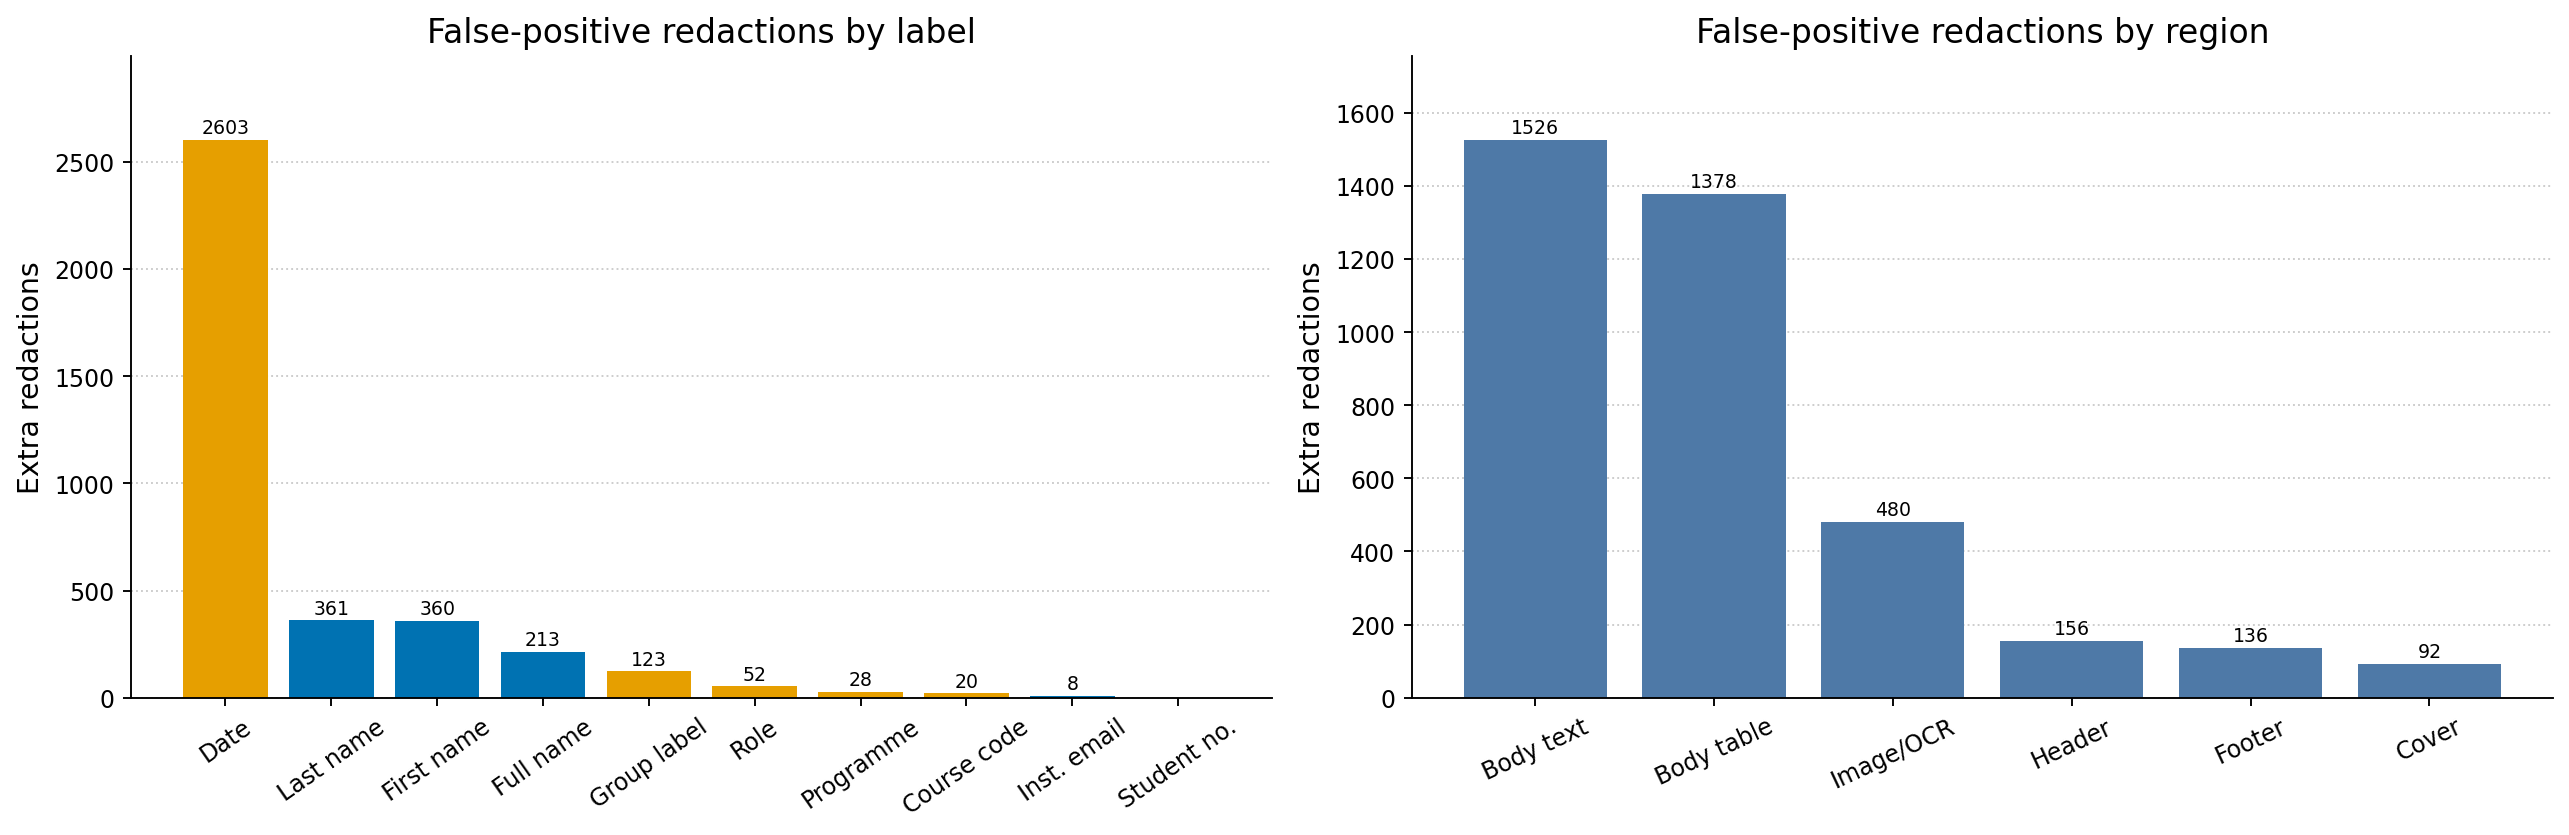

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)

label_plot = extra_by_label.sort_values("extra_redactions", ascending=False)
colors = [COLORS["direct"] if c == "direct" else COLORS["quasi"] for c in label_plot["class"]]
bars = axes[0].bar(label_plot["label"], label_plot["extra_redactions"], color=colors)
axes[0].set_title("False-positive redactions by label")
setup_axis(axes[0], "Extra redactions")
axes[0].tick_params(axis="x", rotation=35)
add_bar_labels(axes[0], bars, offset=12, fontsize=8)

region_plot = extra_by_region.sort_values("extra_redactions", ascending=False)
bars = axes[1].bar(region_plot["region"], region_plot["extra_redactions"], color=COLORS["region"])
axes[1].set_title("False-positive redactions by region")
setup_axis(axes[1], "Extra redactions")
axes[1].tick_params(axis="x", rotation=25)
add_bar_labels(axes[1], bars, offset=8, fontsize=8)

plt.show()

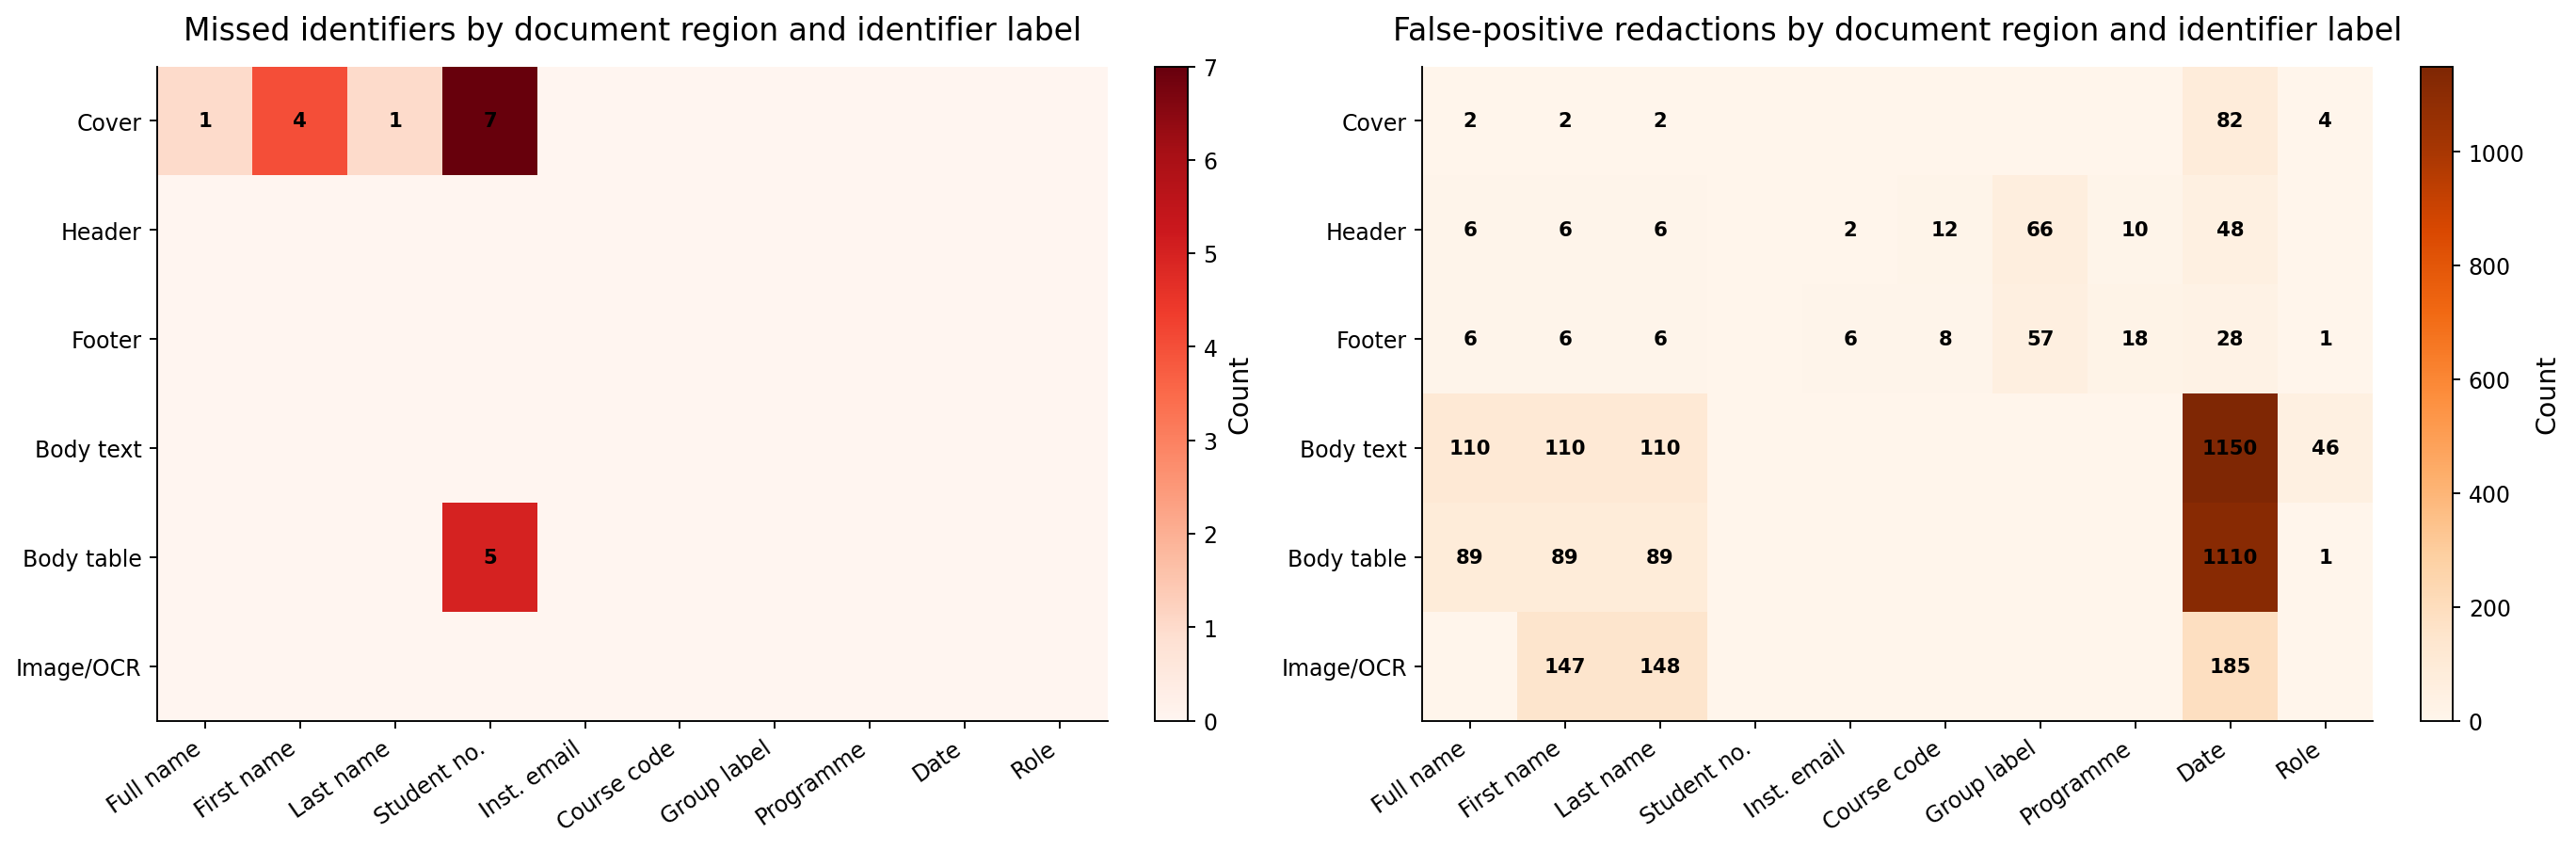

In [18]:
plot_region_label_error_heatmaps(region_label_df)

## 10. Date false-positive diagnosis

The previous section shows that the largest precision problem is the Date label. This section inspects the Date extra redactions more deeply: where they occur, what kinds of strings are detected, and whether detector provenance is available.

In [19]:
date_extra_df = prediction_detail_df[
    (prediction_detail_df["label_raw"] == "Date") &
    (prediction_detail_df["status"] == "extra redaction")
].copy()

all_extra_count = len(all_extra_detail_df)
date_extra_count = len(date_extra_df)
date_share = 100 * date_extra_count / all_extra_count if all_extra_count else 0

headline_df = pd.DataFrame([{
    "all_reconstructed_extra_redactions": all_extra_count,
    "date_reconstructed_extra_redactions": date_extra_count,
    "date_share_of_reconstructed_extra_redactions_percent": round(date_share, 1),
    "date_reference_mentions": int(label_df.loc[label_df["label"] == "Date", "reference_mentions"].iloc[0]),
    "date_precision": round(float(label_df.loc[label_df["label"] == "Date", "precision"].iloc[0]), 3),
    "date_recall": round(float(label_df.loc[label_df["label"] == "Date", "recall"].iloc[0]), 3),
    "date_f1": round(float(label_df.loc[label_df["label"] == "Date", "f1"].iloc[0]), 3),
}])

date_by_region = (
    date_extra_df.groupby("region")
    .size()
    .reset_index(name="date_extra_redactions")
    .sort_values("date_extra_redactions", ascending=False)
)

date_by_surface_type = (
    date_extra_df.groupby("surface_type")
    .size()
    .reset_index(name="date_extra_redactions")
    .sort_values("date_extra_redactions", ascending=False)
)

date_by_detector = (
    date_extra_df.groupby(["detector_group", "provenance"])
    .size()
    .reset_index(name="date_extra_redactions")
    .sort_values("date_extra_redactions", ascending=False)
)

date_surface_examples = (
    date_extra_df.groupby(["normalised_surface", "surface_type"])
    .agg(
        count=("surface", "size"),
        example_surface=("surface", "first"),
        regions=("region", lambda x: ", ".join(sorted(set(x)))),
        documents=("document", "nunique"),
    )
    .reset_index()
    .sort_values("count", ascending=False)
    .head(30)
)

date_by_template_region = date_extra_df.pivot_table(
    index="template",
    columns="region",
    values="surface",
    aggfunc="count",
    fill_value=0,
)
date_by_template_region["Total"] = date_by_template_region.sum(axis=1)
date_by_template_region = date_by_template_region.sort_values("Total", ascending=False)

In [20]:
display(Markdown("### Date false-positive headline"))
display(headline_df)

display(Markdown("### Date extra redactions by region"))
display(date_by_region)

display(Markdown("### Date extra redactions by surface type"))
display(date_by_surface_type)

display(Markdown("### Date extra redactions by detector provenance"))
display(date_by_detector.head(20))

display(Markdown("### Most common Date extra-redaction surfaces"))
display(date_surface_examples)

display(Markdown("### Date extra redactions by template and region"))
display(date_by_template_region)

### Date false-positive headline

,all_reconstructed_extra_redactions,date_reconstructed_extra_redactions,date_share_of_reconstructed_extra_redactions_percent,date_reference_mentions,date_precision,date_recall,date_f1
0,6670,2598,39.0,95,0.035,1.0,0.068


### Date extra redactions by region

,region,date_extra_redactions
1,Body text,1150
0,Body table,1110
5,Image/OCR,185
2,Cover,82
4,Header,48
3,Footer,23


### Date extra redactions by surface type

,surface_type,date_extra_redactions
1,numeric date,1221
3,standalone year,961
2,other number/date-like,401
0,month-name date,15


... (2 outputs left out)

### Most common Date extra-redaction surfaces

,normalised_surface,surface_type,count,example_surface,regions,documents
140,2025,standalone year,205,2025,"Body table, Body text, Cover, Footer, Header",6
251,t2,other number/date-like,145,T2,"Body table, Body text",27
252,t3,other number/date-like,117,T3,"Body table, Body text",24
189,2050,standalone year,84,2050,Body text,28
253,t4,other number/date-like,82,T4,"Body table, Body text",19
122,2007,standalone year,72,2007,Body text,28
169,2026,standalone year,66,2026,"Body table, Body text, Cover, Header",16
129,2014,standalone year,66,2014,Body text,28
123,2008,standalone year,66,2008,"Body table, Body text",28
197,2100,other number/date-like,56,2100,Body text,28


### Date extra redactions by template and region

region,Body table,Body text,Cover,Footer,Header,Image/OCR,Total
template,,,,,,,
project_plan,1110,1148,82,23,48,185,2596
agenda,0,2,0,0,0,0,2


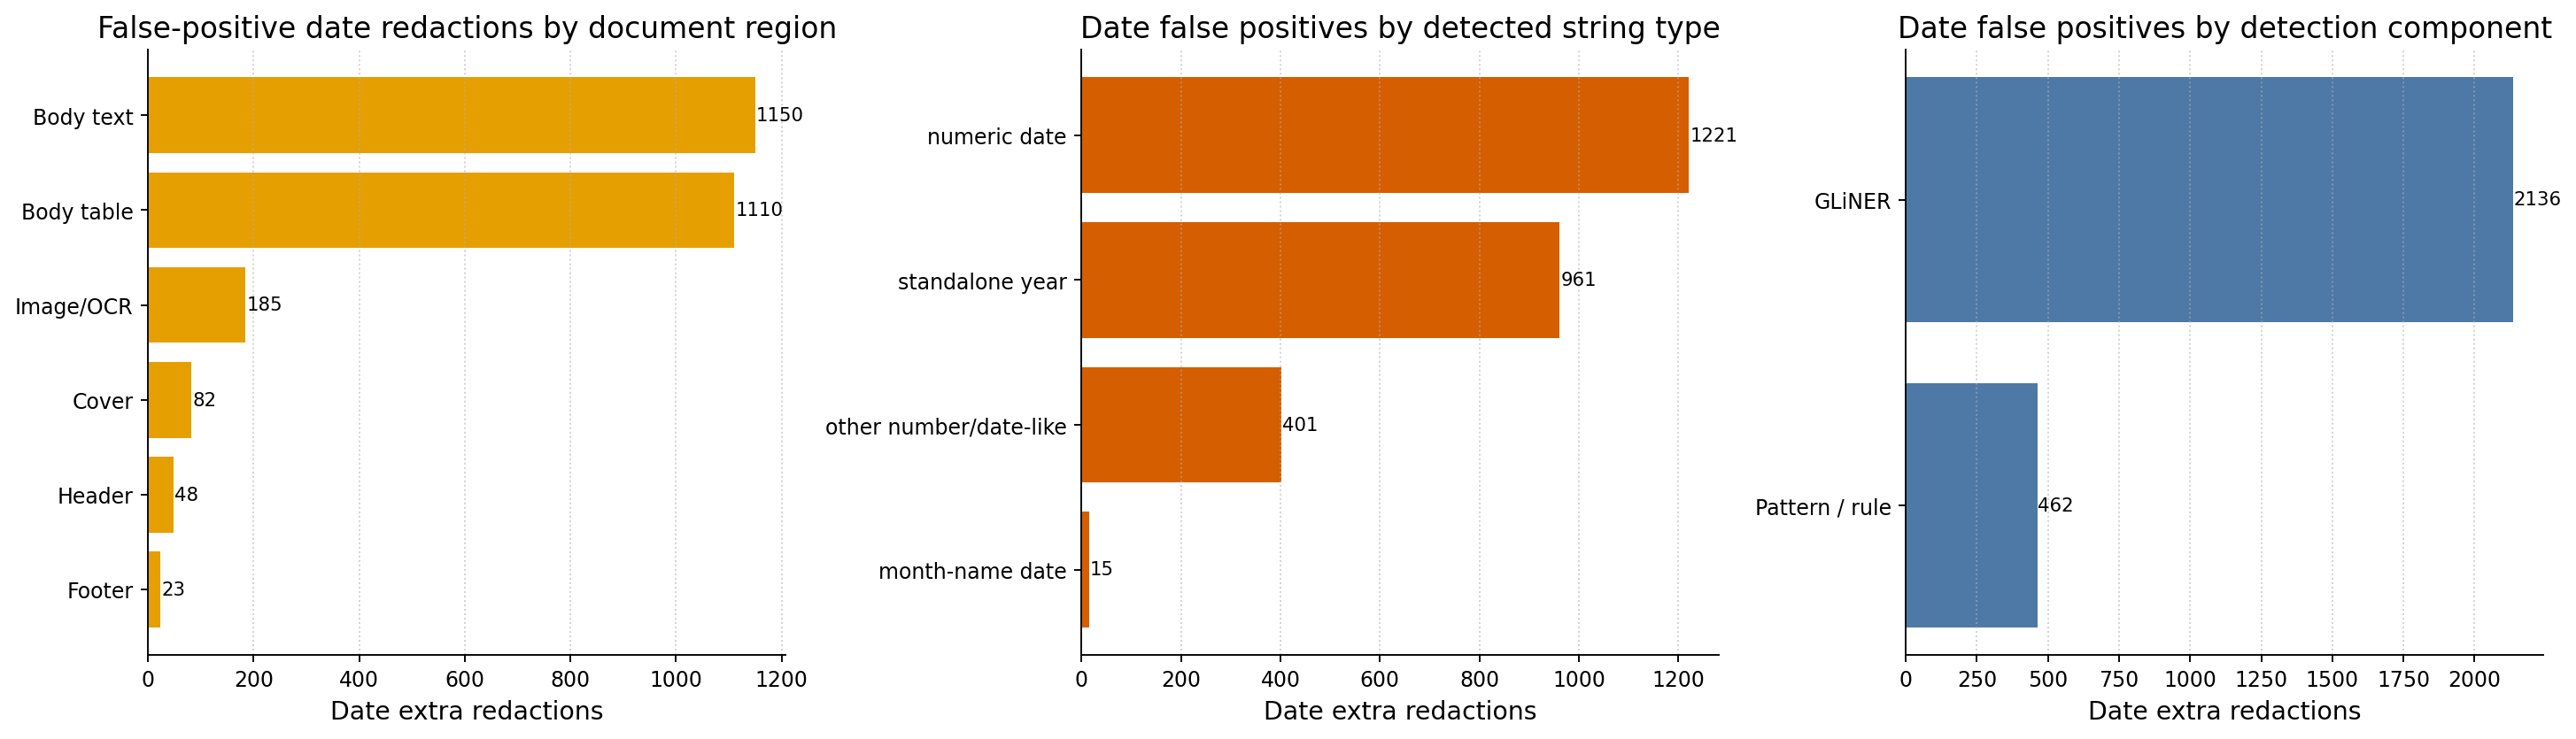

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

region_plot = date_by_region.sort_values("date_extra_redactions", ascending=True)
axes[0].barh(region_plot["region"], region_plot["date_extra_redactions"], color=COLORS["quasi"])
axes[0].set_title("False-positive date redactions by document region")
axes[0].set_xlabel("Date extra redactions")
axes[0].grid(axis="x", linestyle=":", alpha=0.6)
for i, v in enumerate(region_plot["date_extra_redactions"]):
    axes[0].text(v + 2, i, str(int(v)), va="center", fontsize=9)

surface_plot = date_by_surface_type.sort_values("date_extra_redactions", ascending=True)
axes[1].barh(surface_plot["surface_type"], surface_plot["date_extra_redactions"], color=COLORS["extra"])
axes[1].set_title("Date false positives by detected string type")
axes[1].set_xlabel("Date extra redactions")
axes[1].grid(axis="x", linestyle=":", alpha=0.6)
for i, v in enumerate(surface_plot["date_extra_redactions"]):
    axes[1].text(v + 2, i, str(int(v)), va="center", fontsize=9)

detector_plot = (
    date_extra_df.groupby("detector_group")
    .size()
    .reset_index(name="date_extra_redactions")
    .sort_values("date_extra_redactions", ascending=True)
)
axes[2].barh(detector_plot["detector_group"], detector_plot["date_extra_redactions"], color=COLORS["region"])
axes[2].set_title("Date false positives by detection component")
axes[2].set_xlabel("Date extra redactions")
axes[2].grid(axis="x", linestyle=":", alpha=0.6)
for i, v in enumerate(detector_plot["date_extra_redactions"]):
    axes[2].text(v + 2, i, str(int(v)), va="center", fontsize=9)

plt.show()

## 11. Final RQ1 summary (Ai generated)

In [22]:
overall = rq1_result["overall"]

best_labels = label_df.sort_values(["f1", "recall", "precision"], ascending=False).head(4)
weakest_labels = label_df.sort_values(["f1", "precision", "recall"], ascending=[True, True, True]).head(4)
best_regions = region_df.sort_values(["f1", "recall", "precision"], ascending=False).head(3)
weakest_regions = region_df.sort_values(["f1", "precision", "recall"], ascending=[True, True, True]).head(3)
largest_extra_sources = extra_by_label.head(4)

remaining_lines = (
    "\n".join(
        f"- **{r.region} | {r.label}**: {int(r.missed_identifiers)} missed identifier(s)"
        for r in remaining_summary.itertuples(index=False)
    )
    if not remaining_summary.empty
    else "- No reference identifiers remained missed."
)

extra_lines = "\n".join(
    f"- **{r.label}**: {int(r.extra_redactions)} extra redactions; {r.extra_redactions_per_100_reference:.1f} extra redactions per 100 reference mentions"
    for r in largest_extra_sources.itertuples(index=False)
)

summary = f"""
### Scope

RQ1 was evaluated on **{len(docs)} held-out synthetic student documents**. The evaluation set contained **{len(reference_df)} reference identifier mentions**, meaning known correct identifier annotations generated together with the synthetic documents. Of these, **{int((reference_df['class'] == 'direct').sum())}** were direct identifiers and **{int((reference_df['class'] == 'quasi').sum())}** were quasi-identifiers. The evaluation covered **{reference_df['region'].nunique()} document regions**, including **{int((reference_df['source'] == 'image/OCR').sum())} image/OCR-derived mentions**.

### Sanity check

The PerfectModel oracle reached **precision={oracle['overall']['precision']:.3f}**, **recall={oracle['overall']['recall']:.3f}**, and **F1={oracle['overall']['f1']:.3f}**. This confirms that the evaluation code can produce a perfect score when the predicted identifiers exactly match the reference annotations.

### Full pipeline result

The full RQ1 pipeline detected **{overall['tp']}** reference identifier mentions, produced **{overall['fp']}** extra redactions, and missed **{overall['fn']}** reference identifier mentions.

Overall performance was:

- **Precision:** {overall['precision']:.3f}
- **Recall:** {overall['recall']:.3f}
- **F1:** {overall['f1']:.3f}

The central result is that the system has **very high recall** but weaker precision. In privacy terms, this means that the pipeline leaves very little annotated identifying information visible, but it still redacts many spans that were not reference identifiers.

### Strongest label results

{chr(10).join(f"- **{r.label}**: precision={r.precision:.3f}, recall={r.recall:.3f}, F1={r.f1:.3f}, reference mentions={int(r.reference_mentions)}" for r in best_labels.itertuples(index=False))}

### Weakest label results

{chr(10).join(f"- **{r.label}**: precision={r.precision:.3f}, recall={r.recall:.3f}, F1={r.f1:.3f}, reference mentions={int(r.reference_mentions)}" for r in weakest_labels.itertuples(index=False))}

### Strongest region results

{chr(10).join(f"- **{r.region}**: precision={r.precision:.3f}, recall={r.recall:.3f}, F1={r.f1:.3f}, reference mentions={int(r.reference_mentions)}" for r in best_regions.itertuples(index=False))}

### Weakest region results

{chr(10).join(f"- **{r.region}**: precision={r.precision:.3f}, recall={r.recall:.3f}, F1={r.f1:.3f}, reference mentions={int(r.reference_mentions)}" for r in weakest_regions.itertuples(index=False))}

### False-negative interpretation

{remaining_lines}

All remaining missed identifiers are direct identifiers in this run. No quasi-identifier reference mentions were missed. The remaining misses are therefore privacy-relevant, but they are concentrated in only a few locations rather than spread across the full document collection.

### False-positive interpretation

{extra_lines}

The main precision weakness is over-redaction, not missed identifiers. The Date label is the dominant source of extra redactions. This explains why quasi-identifier precision is much lower than direct-identifier precision: the pipeline detects all annotated quasi-identifiers, but it also marks many additional date-like strings that were not part of the reference annotations.

### Date-specific interpretation

The detailed Date inspection shows whether the extra Date redactions come mainly from particular document regions, repeated templates, detector provenance, or surface types such as numeric dates, standalone years, time-like strings, or range-like values. This is useful because it turns the broad precision problem into a concrete improvement target: Date rules and/or Date filtering can be tightened without changing the whole anonymisation pipeline.

### Thesis interpretation

The RQ1 results support the claim that the structure-aware pipeline can detect most direct and quasi-identifiers across heterogeneous student-document regions. Recall is high in every region, including body text, tables, headers, footers, and OCR-derived image text. This is important for anonymisation because missed identifiers are the privacy-critical error type.

However, the results also show that high recall is achieved at the cost of over-redaction. Precision is strong for direct identifiers such as names and student numbers, but weaker for quasi-identifiers, especially Date. Region-wise, cover pages perform best, while headers, footers, and image/OCR text suffer from lower precision. This suggests that the main remaining improvement target for RQ1 is not broad recall coverage, but better filtering of ambiguous quasi-identifiers and repeated-region detections.

A concise result sentence for the paper could be:

**On 16 held-out documents with {len(reference_df)} reference identifier mentions, the full pipeline achieved recall={overall['recall']:.3f} and F1={overall['f1']:.3f}, missing only {overall['fn']} identifiers, but precision was limited to {overall['precision']:.3f} because extra redactions were concentrated in ambiguous quasi-identifier detections, especially Date.**
"""

display(Markdown(summary))


### Scope

RQ1 was evaluated on **84 held-out synthetic student documents**. The evaluation set contained **8768 reference identifier mentions**, meaning known correct identifier annotations generated together with the synthetic documents. Of these, **8306** were direct identifiers and **462** were quasi-identifiers. The evaluation covered **6 document regions**, including **148 image/OCR-derived mentions**.

### Sanity check

The PerfectModel oracle reached **precision=1.000**, **recall=1.000**, and **F1=1.000**. This confirms that the evaluation code can produce a perfect score when the predicted identifiers exactly match the reference annotations.

### Full pipeline result

The full RQ1 pipeline detected **8750** reference identifier mentions, produced **3768** extra redactions, and missed **18** reference identifier mentions.

Overall performance was:

- **Precision:** 0.699
- **Recall:** 0.998
- **F1:** 0.822

The central result is that the system has **very high recall** but weaker precision. In privacy terms, this means that the pipeline leaves very little annotated identifying information visible, but it still redacts many spans that were not reference identifiers.

### Strongest label results

- **Student ID**: precision=1.000, recall=0.971, F1=0.985, reference mentions=407
- **Full name**: precision=0.927, recall=1.000, F1=0.962, reference mentions=2712
- **Last name**: precision=0.877, recall=1.000, F1=0.934, reference mentions=2564
- **First name**: precision=0.877, recall=0.998, F1=0.934, reference mentions=2567

### Weakest label results

- **Date**: precision=0.035, recall=1.000, F1=0.068, reference mentions=95
- **Group label**: precision=0.465, recall=1.000, F1=0.635, reference mentions=107
- **Programme**: precision=0.600, recall=1.000, F1=0.750, reference mentions=42
- **Role**: precision=0.729, recall=1.000, F1=0.843, reference mentions=140

### Strongest region results

- **Cover**: precision=0.963, recall=0.995, F1=0.979, reference mentions=2421
- **Body text**: precision=0.716, recall=1.000, F1=0.834, reference mentions=3843
- **Body table**: precision=0.615, recall=0.998, F1=0.761, reference mentions=2202

### Weakest region results

- **Image/OCR**: precision=0.236, recall=1.000, F1=0.381, reference mentions=148
- **Header**: precision=0.316, recall=1.000, F1=0.480, reference mentions=72
- **Footer**: precision=0.376, recall=1.000, F1=0.547, reference mentions=82

### False-negative interpretation

- **Cover | Student ID**: 7 missed identifier(s)
- **Body table | Student ID**: 5 missed identifier(s)
- **Cover | First name**: 4 missed identifier(s)
- **Cover | Full name**: 1 missed identifier(s)
- **Cover | Last name**: 1 missed identifier(s)

All remaining missed identifiers are direct identifiers in this run. No quasi-identifier reference mentions were missed. The remaining misses are therefore privacy-relevant, but they are concentrated in only a few locations rather than spread across the full document collection.

### False-positive interpretation

- **Date**: 2603 extra redactions; 2740.0 extra redactions per 100 reference mentions
- **Last name**: 361 extra redactions; 14.1 extra redactions per 100 reference mentions
- **First name**: 360 extra redactions; 14.0 extra redactions per 100 reference mentions
- **Full name**: 213 extra redactions; 7.9 extra redactions per 100 reference mentions

The main precision weakness is over-redaction, not missed identifiers. The Date label is the dominant source of extra redactions. This explains why quasi-identifier precision is much lower than direct-identifier precision: the pipeline detects all annotated quasi-identifiers, but it also marks many additional date-like strings that were not part of the reference annotations.

### Date-specific interpretation

The detailed Date inspection shows whether the extra Date redactions come mainly from particular document regions, repeated templates, detector provenance, or surface types such as numeric dates, standalone years, time-like strings, or range-like values. This is useful because it turns the broad precision problem into a concrete improvement target: Date rules and/or Date filtering can be tightened without changing the whole anonymisation pipeline.

### Thesis interpretation

The RQ1 results support the claim that the structure-aware pipeline can detect most direct and quasi-identifiers across heterogeneous student-document regions. Recall is high in every region, including body text, tables, headers, footers, and OCR-derived image text. This is important for anonymisation because missed identifiers are the privacy-critical error type.

However, the results also show that high recall is achieved at the cost of over-redaction. Precision is strong for direct identifiers such as names and student numbers, but weaker for quasi-identifiers, especially Date. Region-wise, cover pages perform best, while headers, footers, and image/OCR text suffer from lower precision. This suggests that the main remaining improvement target for RQ1 is not broad recall coverage, but better filtering of ambiguous quasi-identifiers and repeated-region detections.

A concise result sentence for the paper could be:

**On 16 held-out documents with 8768 reference identifier mentions, the full pipeline achieved recall=0.998 and F1=0.822, missing only 18 identifiers, but precision was limited to 0.699 because extra redactions were concentrated in ambiguous quasi-identifier detections, especially Date.**
